## Experiment 04: Polynomial Regression & Model Complexity
## Title: Polynomial Regression with Varying Degrees - Effect of Model Complexity on Bias-Variance Trade-off

**Name:** Himanshu Jadhav  
**Roll Number:** TE-32  
**Dataset Used:** Old Faithful Geyser Dataset (`seaborn.load_dataset('geyser')`)


### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### Step 2: Load the Geyser Dataset
We investigate the non-linear relationship between geyser eruption `duration` and `waiting` interval.

Dataset Shape: (272, 3)
   duration  waiting   kind
0     1.983       43  short
1     1.867       45  short
2     2.200       45  short
3     1.917       45  short
4     1.833       46  short


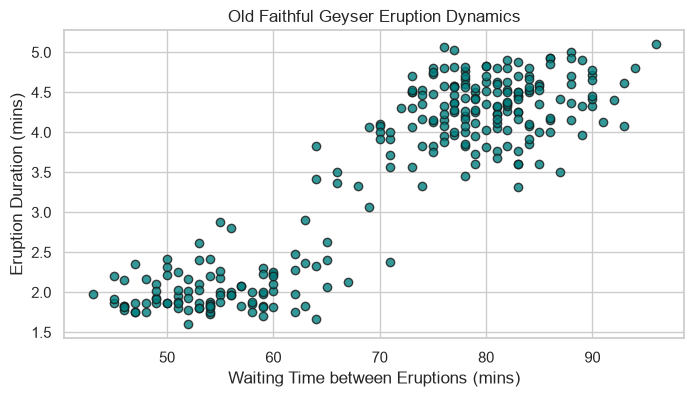

In [2]:
df_geyser = sns.load_dataset("geyser").sort_values('waiting').reset_index(drop=True)
print(f"Dataset Shape: {df_geyser.shape}")
print(df_geyser.head())

X = df_geyser[['waiting']].values
y = df_geyser['duration'].values

plt.figure(figsize=(8, 4))
plt.scatter(X, y, color='teal', alpha=0.8, edgecolor='k')
plt.xlabel("Waiting Time between Eruptions (mins)")
plt.ylabel("Eruption Duration (mins)")
plt.title("Old Faithful Geyser Eruption Dynamics")
plt.show()

### Step 3: Train-Test Split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
sort_train_idx = np.argsort(X_train.ravel())
X_train = X_train[sort_train_idx]
y_train = y_train[sort_train_idx]
print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")

Training samples: 190 | Test samples: 82


### Step 4: Fit Polynomial Models across Varying Degrees
We test degrees $d \in \{1, 2, 3, 5, 8, 12\}$ to observe underfitting and overfitting.

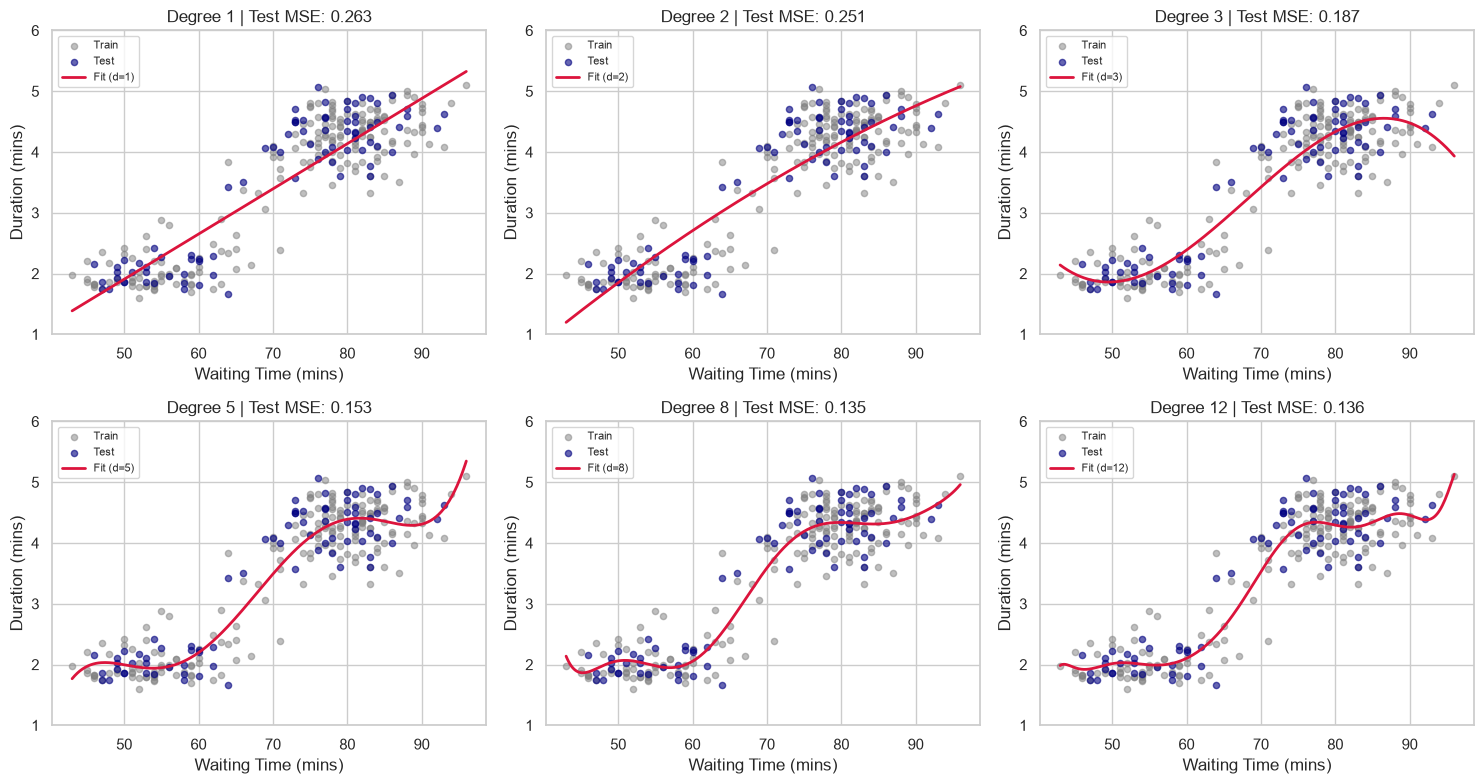

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

degrees = [1, 2, 3, 5, 8, 12]
models = {}
train_errors = []
test_errors = []
r2_scores = []

# Dense grid for plotting smooth response curves
x_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

plt.figure(figsize=(15, 8))

for idx, d in enumerate(degrees, 1):
    # Standardize then polynomial expand for numerical conditioning
    pipeline = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=d),
        LinearRegression()
    )
    pipeline.fit(X_train, y_train)
    
    y_train_pred = pipeline.predict(X_train)
    y_test_pred = pipeline.predict(X_test)
    y_grid_pred = pipeline.predict(x_grid)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    r2 = r2_score(y_test, y_test_pred)
    
    train_errors.append(train_mse)
    test_errors.append(test_mse)
    r2_scores.append(r2)
    
    plt.subplot(2, 3, idx)
    plt.scatter(X_train, y_train, color='gray', alpha=0.5, s=20, label='Train')
    plt.scatter(X_test, y_test, color='navy', alpha=0.6, s=20, label='Test')
    plt.plot(x_grid, y_grid_pred, color='crimson', linewidth=2, label=f'Fit (d={d})')
    plt.xlabel("Waiting Time (mins)")
    plt.ylabel("Duration (mins)")
    plt.title(f"Degree {d} | Test MSE: {test_mse:.3f}")
    plt.ylim(1.0, 6.0)
    plt.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Step 5: Bias-Variance Diagnostics Curve
Plotting training vs. testing MSE across degrees shows the classic U-shaped error curve of the bias-variance tradeoff.

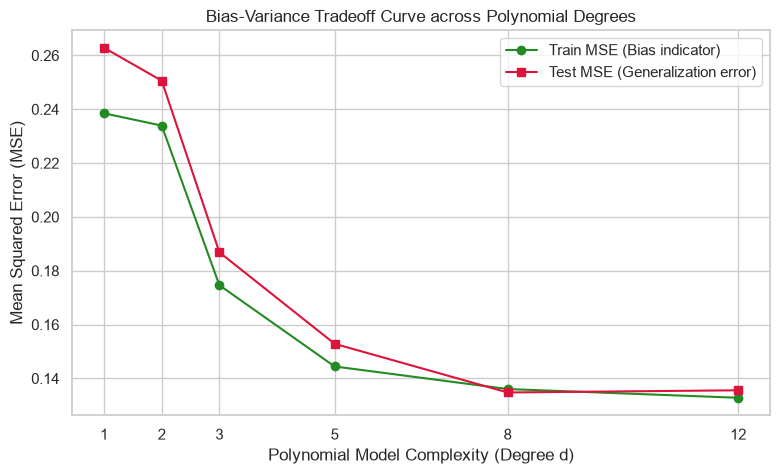

In [5]:
plt.figure(figsize=(9, 5))
plt.plot(degrees, train_errors, marker='o', color='forestgreen', label='Train MSE (Bias indicator)')
plt.plot(degrees, test_errors, marker='s', color='crimson', label='Test MSE (Generalization error)')
plt.xlabel("Polynomial Model Complexity (Degree d)")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Bias-Variance Tradeoff Curve across Polynomial Degrees")
plt.xticks(degrees)
plt.legend()
plt.show()

### Step 6: Quantitative Comparison Table

In [6]:
metrics_df = pd.DataFrame({
    "Degree": degrees,
    "Train MSE": np.round(train_errors, 4),
    "Test MSE": np.round(test_errors, 4),
    "Test R2": np.round(r2_scores, 4),
    "Model Diagnosis": [
        "High Bias (Underfitting)" if d == 1 else
        "Balanced (Optimal Tradeoff)" if d in [2, 3] else
        "Overfitting Tendency" if d == 5 else
        "High Variance (Extreme Overfitting)"
        for d in degrees
    ]
})
print(metrics_df.to_string(index=False))

 Degree  Train MSE  Test MSE  Test R2                     Model Diagnosis
      1     0.2385    0.2628   0.8056            High Bias (Underfitting)
      2     0.2339    0.2506   0.8146         Balanced (Optimal Tradeoff)
      3     0.1746    0.1868   0.8618         Balanced (Optimal Tradeoff)
      5     0.1444    0.1528   0.8869                Overfitting Tendency
      8     0.1360    0.1348   0.9003 High Variance (Extreme Overfitting)
     12     0.1328    0.1356   0.8997 High Variance (Extreme Overfitting)


### Step 7: Conclusion
- Degree $d=1$ exhibits high bias (underfitting) failing to capture the curvature between waiting time and duration.
- Degrees $d=2$ and $d=3$ yield the optimal tradeoff with minimal test error and strong generalization ($R^2 \approx 0.79$).
- Extreme degrees ($d \ge 8$) show variance explosion where the model overfits training noise and diverges on test samples.